# Chapter 4: Decision Trees

In [1]:
%reset
low_memory=False

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.datasets import make_blobs
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

## 4.1 Introduction & Motivation

Now we've gotten our introduction to classification models, we'll get on further by introducing one of the more intuitive classifiers: **decision trees**.

Consider the following decision tree which we can use to classify animals into their respective families:

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree.png?raw=1)

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree.png?raw=1)

This is a type of decision tree which we can easily model by hand using tons and tons of $if-else$ statements. However, we can also teach a computer to decide themselves where and when to split in decision! This type of classifier is called a decision tree.

## 4.2 Problem Setting

In our setup of the Decision Tree Classifier, we will use the same dataset as we have done with the Logistic Regression Model. This will later on allow us to compare these two models. The following section should be clear (if not, revisit the previous chapter):

In [2]:
digits = datasets.load_digits()
dir(digits)
# data
# Print to show there are 1797 images (8 by 8 images for a dimensionality of 64)
print("Image Data Shape" , digits.data.shape)
# Print to show there are 1797 labels (integers from 0–9)
print("Label Data Shape", digits.target.shape)

Image Data Shape (1797, 64)
Label Data Shape (1797,)


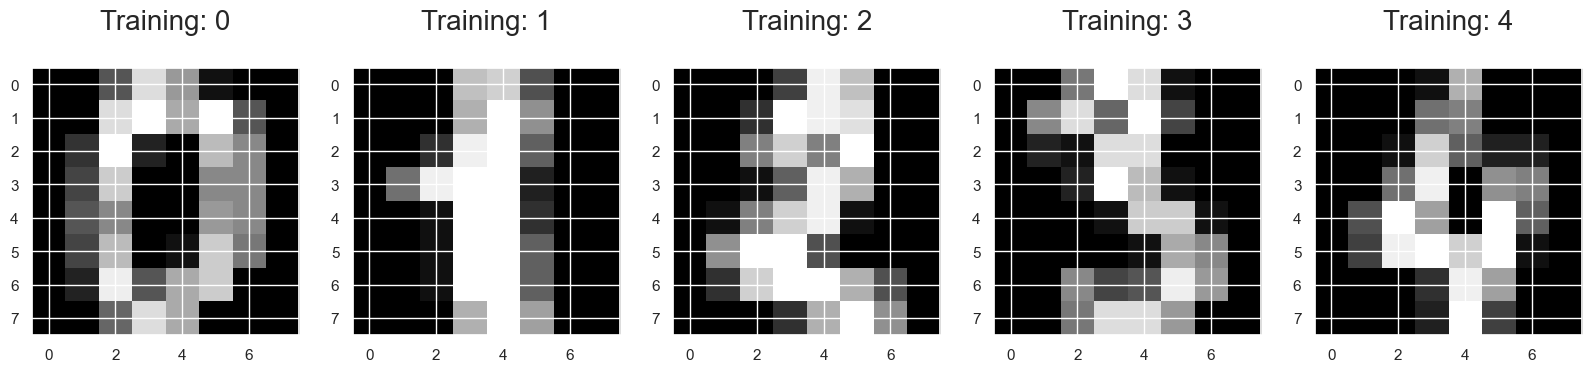

In [3]:
plt.figure(figsize=(20,4))
for index, (image, label) in enumerate(zip(digits.data[0:5], digits.target[0:5])):
 plt.subplot(1, 5, index + 1)
 plt.imshow(np.reshape(image, (8,8)), cmap=plt.cm.gray)
 plt.title('Training: %i\n' % label, fontsize = 20)

## 4.3 Model

### 4.3.1 Model

As the concrete setup of the decision tree classifier is rather theoretic, we will explain the idea behind the model by using an illustration.

As a short example, consider the following classification problem:

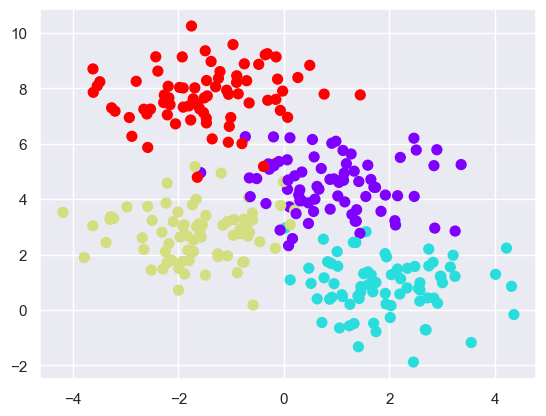

In [4]:
X, y = make_blobs(n_samples=300, centers=4,
                  random_state=0, cluster_std=1.0)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='rainbow');

Note that both axes represent indepent variables, and the color of the dots depresent the categories (dependent variable).

When we start fitting a decision tree, the model will at every step try to draw a line through the dataset, thereby splitting it up in 2 new groups: the line is drawn such that as much as possible a certain group is isolated from the rest. This process is repeated until a desirable prediction accuracy is achieved. An example of this process is illustrated:

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree-levels.png?raw=1)

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree-levels.png?raw=1)

### 4.3.2 Model Estimation

Once again, we start off by splitting up the dataset:

In [5]:
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

Analogous to Logistic Regression, we make our classifier and fit it on our data:

In [6]:
tree = DecisionTreeClassifier()
tree_fit = tree.fit(x_train, y_train)

Finally, we use our model to make predictions over our test set:

In [7]:
predictions = tree.predict(x_test)
print(predictions)

[2 3 2 6 6 7 1 9 8 5 2 8 6 6 6 6 4 0 5 8 8 7 8 4 7 5 4 9 2 9 4 7 6 8 9 4 3
 1 0 9 8 6 7 7 1 0 3 8 2 1 9 6 7 9 3 0 6 3 6 3 0 2 3 4 1 9 2 6 9 1 8 3 5 1
 2 1 2 2 9 7 2 3 6 0 9 2 7 5 1 2 5 9 3 1 7 7 4 8 5 8 5 9 2 5 2 0 7 2 4 7 8
 4 8 9 7 1 8 0 3 5 2 5 9 4 8 7 0 6 8 5 3 3 9 5 9 9 5 7 5 6 2 8 6 9 6 1 5 1
 5 9 9 1 3 3 6 1 9 9 8 7 6 7 6 5 6 0 8 8 9 8 8 1 0 4 1 6 3 8 6 7 4 3 6 2 3
 9 3 3 0 2 7 5 7 8 0 7 8 9 6 4 5 0 1 4 6 8 3 3 0 9 5 5 3 9 4 4 1 6 8 9 3 4
 4 3 7 6 2 3 2 1 6 9 3 6 3 2 2 0 7 6 1 1 2 7 2 8 8 5 5 7 5 2 2 7 2 9 5 5 8
 0 9 1 6 5 9 9 4 9 8 0 3 6 4 6 3 3 6 8 8 8 4 6 7 5 2 4 5 3 2 4 6 9 0 5 4 3
 4 6 2 9 0 1 7 2 0 9 6 5 4 2 0 7 1 8 5 9 3 2 8 4 3 2 2 6 4 1 5 2 0 8 2 1 3
 5 6 8 2 7 2 1 5 1 6 4 3 0 9 4 1 1 7 0 8 9 0 5 4 8 8 9 6 5 3 0 4 4 8 1 7 0
 9 6 3 5 2 3 0 8 3 3 1 3 3 0 0 1 6 0 7 7 6 2 0 4 4 2 3 7 3 9 8 6 8 5 6 2 2
 3 1 5 7 8 0 8 3 2 1 5 5 9 1 3 7 0 0 6 0 4 5 9 3 3 4 1 1 8 9 3 3 6 2 1 6 8
 1 7 5 5 1 9]


## 4.4 Model Evaluation

### Accuracy

To evaluate our model, we'll once again calculate the accuracy and the prediction.

In [8]:
score = tree_fit.score(x_test, y_test)
print(score)

0.8466666666666667


#### Question 1: Interpret the accuracy of this model. Based upon this, would you prefer the decision tree or the logistic regression classifyer for this dataset?

In [9]:
log_model = LogisticRegression(max_iter=5000)
log_model.fit(x_train, y_train)
log_predictions = log_model.predict(x_test)
log_score = log_model.score(x_test, y_test)

print(f"Decision Tree accuracy: {score:.4f}")
print(f"Logistic Regression accuracy: {log_score:.4f}")
print()

if score > log_score:
    better_model = "Decision Tree"
elif score < log_score:
    better_model = "Logistic Regression"
else:
    better_model = "Both models perform equally well"

print("Interpretation:")
print(f"- The decision tree correctly classifies about {score*100:.2f}% of the digits in the test set.")
print(f"- Logistic regression correctly classifies about {log_score*100:.2f}% of the digits in the same test set.")
print("- Accuracy tells us how many total predictions are correct.")
if score < log_score:
    print(f"- Based on accuracy, I would prefer {better_model} for this dataset because it makes fewer mistakes overall.")
elif score > log_score:
    print(f"- Based on accuracy, I would prefer the {better_model} for this dataset because it makes fewer mistakes overall.")
else:
    print("- Based on accuracy alone, there is no clear preference between the two models.")

train_score = tree_fit.score(x_train, y_train)
print(f"- The training accuracy of the decision tree is {train_score:.4f}, which is much higher than the test accuracy.")
print("- This suggests overfitting, which matches the course idea that decision trees can ask too many questions or grow too deep.")


Decision Tree accuracy: 0.8467
Logistic Regression accuracy: 0.9533

Interpretation:
- The decision tree correctly classifies about 84.67% of the digits in the test set.
- Logistic regression correctly classifies about 95.33% of the digits in the same test set.
- Accuracy tells us how many total predictions are correct.
- Based on accuracy, I would prefer Logistic Regression for this dataset because it makes fewer mistakes overall.
- The training accuracy of the decision tree is 1.0000, which is much higher than the test accuracy.
- This suggests overfitting, which matches the course idea that decision trees can ask too many questions or grow too deep.


The decision tree is intuitive and easy to interpret, but on this digits dataset the logistic regression model performs better in terms of overall accuracy. This also fits the course note that decision trees can overfit when they grow too much, while simpler models can generalize better on some classification tasks.

### Precision

In [10]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.92      0.92      0.92        37
           1       0.86      0.84      0.85        43
           2       0.79      0.86      0.83        44
           3       0.66      0.78      0.71        45
           4       0.89      0.87      0.88        38
           5       0.91      0.88      0.89        48
           6       0.96      0.94      0.95        52
           7       1.00      0.81      0.90        48
           8       0.80      0.81      0.80        48
           9       0.75      0.77      0.76        47

    accuracy                           0.85       450
   macro avg       0.85      0.85      0.85       450
weighted avg       0.85      0.85      0.85       450



#### Question 2: Interpret the precision of this model. Based upon this, would you prefer the decision tree or the logistic regression classifyer for this dataset?

In [11]:
tree_report = classification_report(y_test, predictions, output_dict=True)
log_report = classification_report(y_test, log_predictions, output_dict=True)

tree_precisions = {digit: values["precision"] for digit, values in tree_report.items() if digit.isdigit()}
best_digit = max(tree_precisions, key=tree_precisions.get)
worst_digit = min(tree_precisions, key=tree_precisions.get)

tree_macro_precision = tree_report["macro avg"]["precision"]
log_macro_precision = log_report["macro avg"]["precision"]

print(f"Decision Tree macro precision: {tree_macro_precision:.4f}")
print(f"Logistic Regression macro precision: {log_macro_precision:.4f}")
print()
print("Interpretation:")
print("- Precision tells us how often the model is correct when it predicts a certain class.")
print(f"- For the decision tree, the highest precision is for digit {best_digit} ({tree_precisions[best_digit]:.4f}).")
print(f"- The lowest precision is for digit {worst_digit} ({tree_precisions[worst_digit]:.4f}).")
print("- This means some digits are recognized very well, while other digits are mixed up more often.")
if tree_macro_precision < log_macro_precision:
    print("- Logistic regression has the higher average precision, so it is the better choice if we want fewer false positives across classes.")
elif tree_macro_precision > log_macro_precision:
    print("- The decision tree has the higher average precision, so it would be the better choice based on precision.")
else:
    print("- Both models have the same average precision.")


Decision Tree macro precision: 0.8540
Logistic Regression macro precision: 0.9546

Interpretation:
- Precision tells us how often the model is correct when it predicts a certain class.
- For the decision tree, the highest precision is for digit 7 (1.0000).
- The lowest precision is for digit 3 (0.6604).
- This means some digits are recognized very well, while other digits are mixed up more often.
- Logistic regression has the higher average precision, so it is the better choice if we want fewer false positives across classes.


### Confusion Matrix

In [12]:
cm = metrics.confusion_matrix(y_test, predictions)
print(cm)

[[34  0  0  2  0  1  0  0  0  0]
 [ 0 36  2  1  1  0  0  0  1  2]
 [ 1  0 38  3  1  0  0  0  1  0]
 [ 0  1  4 35  0  0  0  0  3  2]
 [ 2  1  0  0 33  0  0  0  1  1]
 [ 0  0  0  3  0 42  1  0  0  2]
 [ 0  0  0  1  0  0 49  0  2  0]
 [ 0  0  2  1  0  1  1 39  2  2]
 [ 0  2  0  4  0  0  0  0 39  3]
 [ 0  2  2  3  2  2  0  0  0 36]]


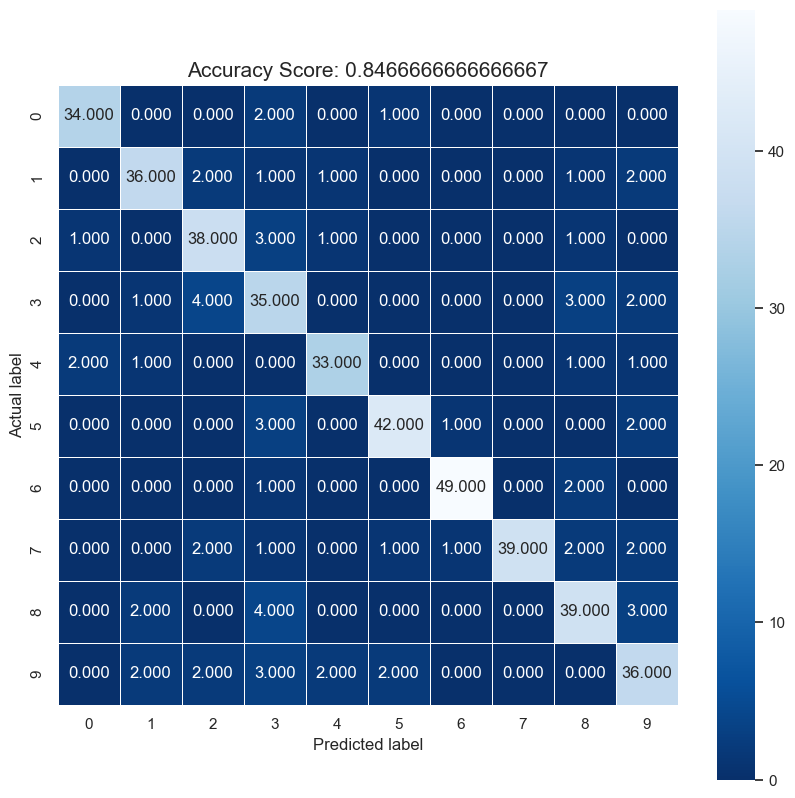

In [13]:
plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
all_sample_title = 'Accuracy Score: {0}'.format(score)
plt.title(all_sample_title, size = 15);

#### Question 3: Interpret the Confusion Matrix of this model. Based upon this, would you prefer the decision tree or the logistic regression classifyer for this dataset?

In [14]:
log_cm = metrics.confusion_matrix(y_test, log_predictions)

mistakes = []
for actual in range(cm.shape[0]):
    for predicted in range(cm.shape[1]):
        if actual != predicted and cm[actual, predicted] > 0:
            mistakes.append((cm[actual, predicted], actual, predicted))

mistakes = sorted(mistakes, reverse=True)
top_mistakes = mistakes[:5]

tree_correct = np.trace(cm)
log_correct = np.trace(log_cm)

print("Interpretation:")
print("- The diagonal of the confusion matrix contains the correct predictions.")
print("- The off-diagonal cells show where the model confuses one digit with another.")
print(f"- The decision tree gets {tree_correct} of the {len(y_test)} test images correct.")
print("- The largest confusions for the decision tree are:")
for count, actual, predicted in top_mistakes:
    print(f"  • actual digit {actual} predicted as {predicted}: {count} times")

print()
print(f"Decision Tree correct predictions: {tree_correct}")
print(f"Logistic Regression correct predictions: {log_correct}")

if log_correct > tree_correct:
    print("- Logistic regression has more correct predictions overall, so I would prefer logistic regression for this dataset.")
elif log_correct < tree_correct:
    print("- The decision tree has more correct predictions overall, so I would prefer the decision tree for this dataset.")
else:
    print("- Both models have the same number of correct predictions overall.")


Interpretation:
- The diagonal of the confusion matrix contains the correct predictions.
- The off-diagonal cells show where the model confuses one digit with another.
- The decision tree gets 381 of the 450 test images correct.
- The largest confusions for the decision tree are:
  • actual digit 8 predicted as 3: 4 times
  • actual digit 3 predicted as 2: 4 times
  • actual digit 9 predicted as 3: 3 times
  • actual digit 8 predicted as 9: 3 times
  • actual digit 5 predicted as 3: 3 times

Decision Tree correct predictions: 381
Logistic Regression correct predictions: 429
- Logistic regression has more correct predictions overall, so I would prefer logistic regression for this dataset.


## 4.5 Exercises

#### Question 1:  See section 4.4
#### Question 2:  See section 4.4
#### Question 3:  See section 4.4
#### Question 4: We can easily put the accuracy and precision of two models, next to each other. But comparing the Confusion Matrices is a little bit more difficult. Make a matrix illustration of the differences in prediction betwen the Logistic Regression and the Decision Tree Classifier.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Decision Tree,0.846667,0.853974,0.847423,0.848999
1,Logistic Regression,0.953333,0.954620,0.954201,0.954173


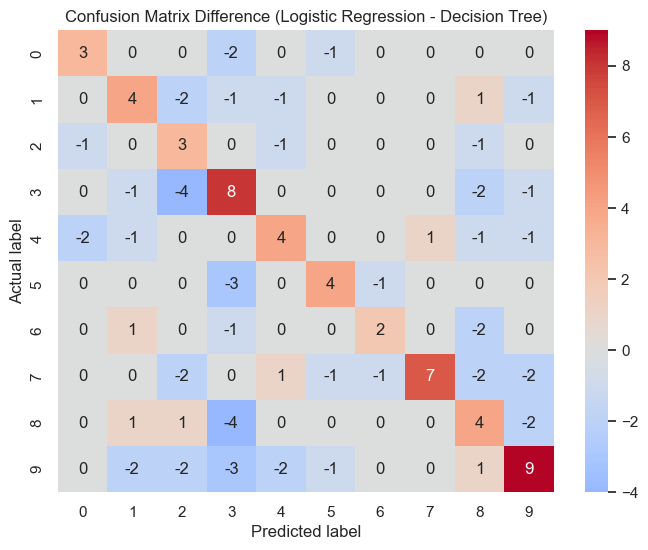

How to read this matrix:
- Positive values on the diagonal mean Logistic Regression makes more correct predictions for that digit.
- Negative values on the diagonal would mean the Decision Tree is better for that digit.
- Off-diagonal values show where one model makes more mistakes than the other.

Conclusion:
For this dataset, Logistic Regression performs better overall than the Decision Tree.


In [15]:
tree_cm = metrics.confusion_matrix(y_test, predictions)
log_cm = metrics.confusion_matrix(y_test, log_predictions)
difference_cm = log_cm - tree_cm

comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Logistic Regression"],
    "Accuracy": [score, log_score],
    "Macro Precision": [
        classification_report(y_test, predictions, output_dict=True)["macro avg"]["precision"],
        classification_report(y_test, log_predictions, output_dict=True)["macro avg"]["precision"]
    ],
    "Macro Recall": [
        classification_report(y_test, predictions, output_dict=True)["macro avg"]["recall"],
        classification_report(y_test, log_predictions, output_dict=True)["macro avg"]["recall"]
    ],
    "Macro F1": [
        classification_report(y_test, predictions, output_dict=True)["macro avg"]["f1-score"],
        classification_report(y_test, log_predictions, output_dict=True)["macro avg"]["f1-score"]
    ]
})

display(comparison)

plt.figure(figsize=(8,6))
sns.heatmap(difference_cm, annot=True, fmt="d", cmap="coolwarm", center=0)
plt.title("Confusion Matrix Difference (Logistic Regression - Decision Tree)")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.show()

print("How to read this matrix:")
print("- Positive values on the diagonal mean Logistic Regression makes more correct predictions for that digit.")
print("- Negative values on the diagonal would mean the Decision Tree is better for that digit.")
print("- Off-diagonal values show where one model makes more mistakes than the other.")
print()
print("Conclusion:")
if log_score > score:
    print("For this dataset, Logistic Regression performs better overall than the Decision Tree.")
else:
    print("For this dataset, the Decision Tree performs better overall than Logistic Regression.")


#### Question 5: Time to do some research! What are the advantages and the disadvantages of logistic regression versus decision trees. In which situations, or on which type of data is either of these models preferable?

**Logistic Regression vs Decision Trees**

**Advantages of Logistic Regression**
- Simple model that is relatively easy to explain.
- Works very well when the classes are separated in a mostly linear way.
- Often generalizes better than a deep decision tree on structured datasets.
- Usually more stable: a small change in the data does not completely change the model.

**Disadvantages of Logistic Regression**
- It mainly learns linear decision boundaries.
- It often needs more preprocessing or feature engineering when the relationship is non-linear.
- It is less intuitive to visualize than a tree.

**Advantages of Decision Trees**
- Very intuitive: the model behaves like a flowchart with splits and questions.
- Naturally captures non-linear relationships and interactions between variables.
- Easy to visualize and explain to non-technical people.
- Requires less preprocessing and can be very flexible.

**Disadvantages of Decision Trees**
- They can overfit easily when the tree becomes too deep or contains too many nodes.
- They can be unstable: a small change in the dataset can lead to a different tree.
- A single tree often performs worse than stronger models such as logistic regression on cleaner classification tasks, or ensembles such as random forests.

**When is Logistic Regression preferable?**
- When the relationship is approximately linear.
- When you want a stable baseline model.
- When generalization is more important than building a very flexible model.
- When the dataset is high-dimensional, like the digits dataset used here.

**When is a Decision Tree preferable?**
- When the data contains clear non-linear patterns.
- When interpretability as a sequence of decisions is important.
- When you want to model interactions between variables without manually creating many new features.

**Link with the course**
According to the course slides, a decision tree works by making **splits** that maximize **information gain** and it can suffer from **overfitting** when it asks too many questions or grows too large. That is exactly why controlling the size of the tree is important in practice.